<a href="https://colab.research.google.com/github/peter-adepoju/math-neuro-ml/blob/main/week4/lesson15/Lesson15_Teaching_Notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **MAMBA: Mathematical Sciences for Brain Data**
## Lesson 15 — Multidimensional Optimisation: Valleys, Scaling and Momentum

**Course:** MAMBA: Mathematical Sciences for Brain Data\
**Week:** Week 4 — Calculus II\
**Lesson:** Lesson 15\
**Notebook type:** Teaching notebook

> *"Gradient descent always walks straight downhill. In a narrow valley, straight downhill points at the opposite wall."*

---

### From one parameter to many

Lesson 12 fitted one parameter by gradient descent; Lesson 14 introduced gradients, contours and Hessians for many. This lesson puts them together: the **vector update**

$$\boldsymbol\theta_{k+1} = \boldsymbol\theta_k - \eta\,\nabla L(\boldsymbol\theta_k),$$

where $L:\mathbb{R}^p\to\mathbb{R}$ is a fixed objective, $\boldsymbol\theta\in\mathbb{R}^p$ a parameter column vector (a NumPy array of shape `(p,)`), $\eta>0$ a learning rate and $k$ the **iteration index** (an algorithmic counter, not biological time).

We will see:
1. how to build an optimiser you can **trust**: simultaneous updates, recorded histories, stop reasons, gradient checks;
2. why the **eigenvalues of the Hessian** decide stability and speed, exactly, for quadratics;
3. why **elongated valleys** (large condition number) make gradient descent zig-zag and crawl;
4. how **scaling, preconditioning and momentum** change the update geometry, and what they cannot fix;
5. how **regularisation and validation monitoring** separate a good optimisation from a good model.

The mini-lab trains a linear decoder of hand velocity from 170 motor-cortex neurons by gradient descent: on raw firing rates the problem has a condition number of about a hundred million and barely moves; standardised, it converges in a few dozen steps; with little training data, the decoder that generalises best is **not** the one the optimiser converges to.

### Import Dependencies

In [1]:
# SETUP CELL
import numpy as np
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from dataclasses import dataclass, field

RNG = np.random.default_rng(42)

# The same colourblind-conscious palette and markers as Lessons 1-14.
PALETTE = ['#0072B2', '#D55E00', '#009E73', '#CC79A7', '#E69F00', '#56B4E9']
MARKERS = ['o', 's', '^', 'D', 'v', 'P']
LINESTYLES = ['-', '--', ':', '-.']

print("Setup complete.")

Setup complete.


### Interactive and animated plotting tools

As before, each static figure is followed by a **Plotly version** that you can zoom, pan, hover over, and save. Sliders are pre-computed frames, so they work offline and in a static viewer.

In [2]:
# INTERACTIVE/ANIMATION SETUP
import sys
import plotly.io as pio

if 'google.colab' not in sys.modules:
    pio.renderers.default = 'notebook_connected'
pio.templates['plotly_white'].layout.xaxis.showgrid = False
pio.templates['plotly_white'].layout.yaxis.showgrid = False

PLOTLY_CONFIG = {'displaylogo': False, 'responsive': True, 'scrollZoom': True,
                 'toImageButtonOptions': {'format': 'png', 'scale': 2}}

def play_pause_and_slider(labels, prefix, duration=150):
    # Play/Pause buttons and a frame slider, as used in Lessons 1-14.
    buttons = [dict(
        type='buttons', showactive=False, x=0.0, y=-0.12, xanchor='left', yanchor='top',
        buttons=[
            dict(label='Play', method='animate', args=[None, {'frame': {'duration': duration, 'redraw': True}, 'transition': {'duration': 0}, 'fromcurrent': True}]),
            dict(label='Pause', method='animate', args=[[None], {'frame': {'duration': 0, 'redraw': False}, 'mode': 'immediate'}]),
        ],
    )]
    sliders = [dict(
        active=0, currentvalue={'prefix': prefix}, pad={'t': 50},
        steps=[dict(label=str(lab), method='animate', args=[[str(k)], {'mode': 'immediate', 'frame': {'duration': 0, 'redraw': True}, 'transition': {'duration': 0}}])
               for k, lab in enumerate(labels)],
    )]
    return buttons, sliders

print('Interactive plotting and animation tools are ready.')

Interactive plotting and animation tools are ready.


# **Motivation and Retrieval: One Step by Hand**

Take the two-parameter objective

$$L(\theta_1, \theta_2) = \tfrac12\big[(\theta_1 - 2)^2 + 4(\theta_2 + 1)^2\big].$$

- Its minimum is at $\boldsymbol\theta^\star = (2, -1)$, where $L = 0$.
- Its gradient is $\nabla L = \big(\theta_1 - 2,\ 4(\theta_2 + 1)\big)^{\mathsf T}$, shape `(2,)`; its Hessian is $\operatorname{diag}(1, 4)$ (Lesson 14).
- From $\boldsymbol\theta_0 = (0, 0)$ with $\eta = 0.1$: $\nabla L(\boldsymbol\theta_0) = (-2, 4)$, so $\boldsymbol\theta_1 = (0, 0) - 0.1\,(-2, 4) = (0.2, -0.4)$.

**Prediction before running:** which coordinate gets closer to its target faster? The error in $\theta_1$ shrinks by the factor $1 - 0.1\times1 = 0.9$ per step; the error in $\theta_2$ by $1 - 0.1\times4 = 0.6$. The **more curved** direction converges faster, for the same learning rate. The rest of the lesson builds on this observation.

In [3]:
def L_demo(th):
    return 0.5 * ((th[0] - 2)**2 + 4 * (th[1] + 1)**2)
def g_demo(th):
    return np.array([th[0] - 2, 4 * (th[1] + 1)])

theta0 = np.array([0.0, 0.0])
theta1 = theta0 - 0.1 * g_demo(theta0)
print("gradient at theta0:", g_demo(theta0), "  theta1 =", theta1, "  (hand calculation: (0.2, -0.4))")
err0, err1 = theta0 - np.array([2, -1]), theta1 - np.array([2, -1])
print("per-coordinate error ratios after one step:", err1 / err0, " (predicted 1 - eta * curvature = 0.9 and 0.6)")

gradient at theta0: [-2.  4.]   theta1 = [ 0.2 -0.4]   (hand calculation: (0.2, -0.4))
per-coordinate error ratios after one step: [0.9 0.6]  (predicted 1 - eta * curvature = 0.9 and 0.6)


# **Part 1: A Vector Optimiser You Can Trust**

The update must be **simultaneous**: compute the whole gradient at $\boldsymbol\theta_k$, then change all components. Updating $\theta_1$ first and then computing $\partial L/\partial\theta_2$ at the half-updated point is a different (and usually unintended) algorithm.

A trustworthy optimiser also:
- **records histories** of parameters, objective, gradient norm, step norm and learning rate, **including the initial state** (iteration 0), with `.copy()` so later updates do not overwrite stored values;
- **checks for non-finite values** and reports divergence;
- uses **explicit, scale-aware stopping rules** (Lesson 12), with a hard maximum number of iterations:
  - gradient: $\lVert\nabla L(\boldsymbol\theta_k)\rVert_2 \le \varepsilon_g$;
  - step: $\lVert\boldsymbol\theta_{k+1} - \boldsymbol\theta_k\rVert_2 \le \varepsilon_x(1 + \lVert\boldsymbol\theta_k\rVert_2)$;
  - objective: $\lvert L_{k+1} - L_k\rvert \le \varepsilon_L(1 + \lvert L_k\rvert)$. This one is a **stall detector**, not a convergence test: a plateau, a tiny learning rate or a bouncing iterate (Part 2's boundary case) also make the objective stop changing. The optimiser below therefore reports it as "objective stalled", never as success;
- **reports why it stopped**, and never calls "ran out of iterations" convergence.

Before any of this, **check the gradient** against central differences: more iterations never fix a wrong gradient.

The function below implements vanilla gradient descent and, through the parameter `beta`, the heavy-ball **momentum** of Part 5 (with `beta = 0` it is exactly vanilla gradient descent).

In [4]:
@dataclass
class OptResult:
    # Everything needed to diagnose a run. Histories include iteration 0 and are aligned by iteration.
    theta: np.ndarray                  # final parameters, shape (p,)
    objective: float                   # final objective value
    theta_hist: np.ndarray             # (k + 1, p)
    obj_hist: np.ndarray               # (k + 1,)
    grad_norm_hist: np.ndarray         # (k + 1,)  gradient norm at each stored iterate
    step_norm_hist: np.ndarray         # (k + 1,)  norm of the step that produced each iterate (0 for iteration 0)
    lr_hist: np.ndarray                # (k + 1,)
    n_iter: int
    stop_reason: str
    success: bool                      # True only if a tolerance criterion was met with finite values

def gradient_descent(objective, gradient, theta0, learning_rate, beta=0.0, max_steps=2000,
                     grad_tol=1e-8, step_tol=1e-12, rel_loss_tol=None, diverge_at=1e6):
    # Full-batch gradient descent with optional heavy-ball momentum:
    #   v_{k+1} = beta v_k + grad L(theta_k);   theta_{k+1} = theta_k - eta v_{k+1};   v_0 = 0.
    theta = np.array(theta0, dtype=float).copy()
    if theta.ndim != 1:
        raise ValueError("theta0 must be a 1-D array of shape (p,)")
    if not (learning_rate > 0 and 0 <= beta < 1 and max_steps >= 1):
        raise ValueError("need learning_rate > 0, 0 <= beta < 1, max_steps >= 1")
    v = np.zeros_like(theta)
    L, g = float(objective(theta)), np.asarray(gradient(theta), float)
    th_h, L_h, g_h, s_h, lr_h = [theta.copy()], [L], [np.linalg.norm(g)], [0.0], [learning_rate]
    reason = 'max_steps reached (NOT converged)'
    for k in range(max_steps):
        if not (np.isfinite(L) and np.all(np.isfinite(g))):
            reason = 'non-finite objective or gradient'; break
        if np.linalg.norm(g) <= grad_tol:
            reason = 'gradient tolerance'; break
        v = beta * v + g                                  # all components use the gradient at the SAME theta
        step = -learning_rate * v
        theta_new = theta + step
        L_new, g_new = float(objective(theta_new)), np.asarray(gradient(theta_new), float)
        th_h.append(theta_new.copy()); L_h.append(L_new); g_h.append(np.linalg.norm(g_new))
        s_h.append(np.linalg.norm(step)); lr_h.append(learning_rate)
        if not (np.all(np.isfinite(theta_new)) and np.isfinite(L_new)) or np.linalg.norm(theta_new) > diverge_at * (1 + np.linalg.norm(th_h[0])):
            theta, L, g = theta_new, L_new, g_new
            reason = 'diverged'; break
        small_step = np.linalg.norm(step) <= step_tol * (1 + np.linalg.norm(theta))
        small_change = rel_loss_tol is not None and abs(L_new - L) <= rel_loss_tol * (1 + abs(L))
        theta, L, g = theta_new, L_new, g_new
        if small_step:
            reason = 'step tolerance'; break
        if small_change:
            reason = 'objective stalled (NOT a convergence test)'; break
    return OptResult(theta, L, np.array(th_h), np.array(L_h), np.array(g_h), np.array(s_h), np.array(lr_h),
                     len(L_h) - 1, reason, reason in ('gradient tolerance', 'step tolerance'))

def check_gradient(objective, gradient, theta, h=1e-6):
    # Largest scale-aware relative error between the analytic gradient and central differences.
    theta = np.asarray(theta, float); g = np.asarray(gradient(theta), float); num = np.zeros_like(theta)
    for i in range(theta.size):
        e = np.zeros_like(theta); e[i] = h * (1 + abs(theta[i]))
        num[i] = (objective(theta + e) - objective(theta - e)) / (2 * e[i])
    return float(np.max(np.abs(g - num)) / max(1.0, np.max(np.abs(num))))

print("gradient check on the demo objective:", f"{check_gradient(L_demo, g_demo, np.array([0.3, 0.7])):.1e}")
res = gradient_descent(L_demo, g_demo, theta0, 0.1, grad_tol=1e-8)
print(f"stop reason: {res.stop_reason};  iterations: {res.n_iter};  final theta {np.round(res.theta, 8)};  final objective {res.objective:.2e}")
print("history shapes:", res.theta_hist.shape, res.obj_hist.shape, res.grad_norm_hist.shape, " (iteration 0 included)")

gradient check on the demo objective: 6.9e-11
stop reason: gradient tolerance;  iterations: 182;  final theta [ 1.99999999 -1.        ];  final objective 4.42e-17
history shapes: (183, 2) (183,) (183,)  (iteration 0 included)


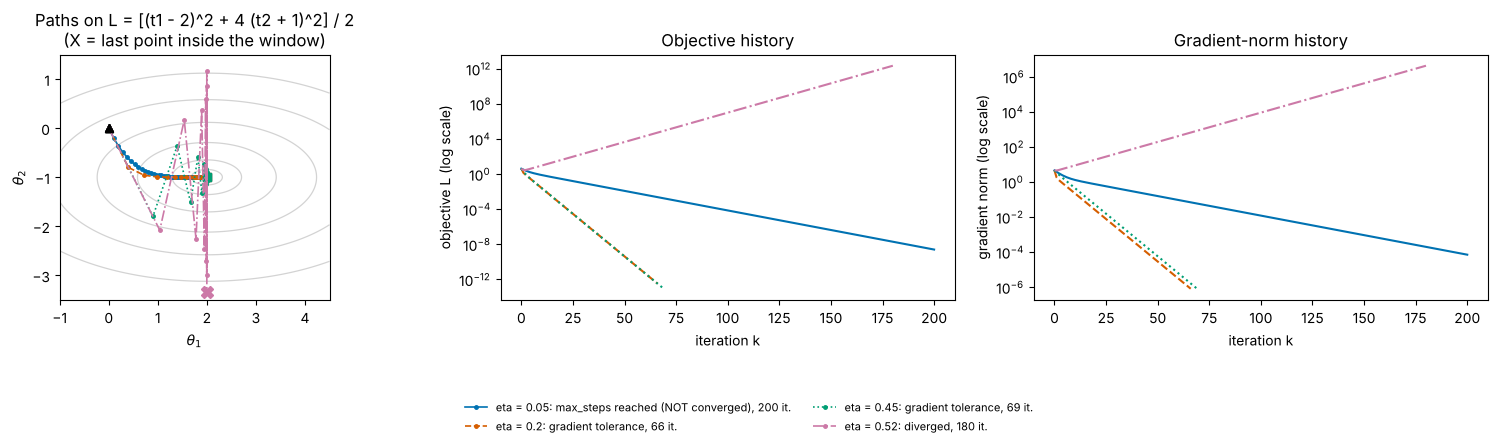

eta = 0.05 : max_steps reached (NOT converged)  after  200 iterations;  final objective 2.46e-09
eta = 0.2  : gradient tolerance                 after   66 iterations;  final objective 3.23e-13
eta = 0.45 : gradient tolerance                 after   69 iterations;  final objective 8.46e-14
eta = 0.52 : diverged                           after  180 iterations;  final objective 2.16e+12


In [5]:
def contour_axes(ax, objective, xlim, ylim, levels, n=241):
    xs, ys = np.linspace(*xlim, n), np.linspace(*ylim, n)
    XX, YY = np.meshgrid(xs, ys)
    ZZ = np.array([[objective(np.array([a, b])) for a, b in zip(ra, rb)] for ra, rb in zip(XX, YY)])
    ax.contour(XX, YY, ZZ, levels=levels, colors=['lightgrey'], linewidths=0.9)
    ax.set_aspect('equal'); ax.set_xlim(*xlim); ax.set_ylim(*ylim)

def diagnostic_figure(results, labels, objective, xlim, ylim, levels, title):
    # Path on controlled contours, objective history and gradient-norm history, read together.
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
    contour_axes(axes[0], objective, xlim, ylim, levels)
    for r, lab, c, ls in zip(results, labels, PALETTE, LINESTYLES * 3):
        P = r.theta_hist
        inside = (P[:, 0] >= xlim[0]) & (P[:, 0] <= xlim[1]) & (P[:, 1] >= ylim[0]) & (P[:, 1] <= ylim[1])
        last = len(P) if inside.all() else int(np.argmax(~inside))      # never clip a divergent path silently
        axes[0].plot(P[:last, 0], P[:last, 1], ls, color=c, marker='o', ms=2.5, lw=1.2, label=f'{lab}: {r.stop_reason}, {r.n_iter} it.')
        axes[0].plot(*P[0], 'k^', ms=6)
        if last == len(P):
            axes[0].plot(*P[-1], 's', color=c, ms=6)
        else:
            axes[0].plot(*P[last - 1], 'X', color=c, ms=9)                 # last visible point of a path that leaves the window
        axes[1].semilogy(np.maximum(r.obj_hist, 1e-18), ls, color=c, lw=1.5)
        axes[2].semilogy(np.maximum(r.grad_norm_hist, 1e-18), ls, color=c, lw=1.5)
    axes[0].set_xlabel('$\\theta_1$'); axes[0].set_ylabel('$\\theta_2$'); axes[0].set_title(title)
    axes[1].set_xlabel('iteration k'); axes[1].set_ylabel('objective L (log scale)'); axes[1].set_title('Objective history')
    axes[2].set_xlabel('iteration k'); axes[2].set_ylabel('gradient norm (log scale)'); axes[2].set_title('Gradient-norm history')
    fig.legend(*axes[0].get_legend_handles_labels(), loc='lower center', ncol=min(2, len(results)), fontsize=8, frameon=False)
    plt.tight_layout(rect=[0, 0.17, 1, 1]); plt.show()

runs = [gradient_descent(L_demo, g_demo, theta0, eta, max_steps=200, grad_tol=1e-6) for eta in [0.05, 0.2, 0.45, 0.52]]
diagnostic_figure(runs, ['eta = 0.05', 'eta = 0.2', 'eta = 0.45', 'eta = 0.52'], L_demo, (-1, 4.5), (-3.5, 1.5),
                  [0.05, 0.25, 1, 2.5, 5, 9], 'Paths on L = [(t1 - 2)^2 + 4 (t2 + 1)^2] / 2\n(X = last point inside the window)')
for eta, r in zip([0.05, 0.2, 0.45, 0.52], runs):
    print(f"eta = {eta:<5}: {r.stop_reason:<34} after {r.n_iter:4d} iterations;  final objective {r.objective:.2e}")

Read the path **and** the histories together. With $\eta = 0.05$ the path is smooth but slow (the flat $\theta_1$ direction shrinks by only 0.95 per step) and the iteration budget runs out. With $\eta = 0.2$ it is fast and direct. With $\eta = 0.45$ the steep $\theta_2$ direction overshoots: the path zig-zags across the valley but still converges. With $\eta = 0.52$ the $\theta_2$ error is multiplied by $1 - 0.52\times4 = -1.08$ each step: the path bounces with growing amplitude, leaves the window (marked X) and the optimiser reports **divergence** once the parameters exceed a million times their initial size. A path that only *looks* close to the minimum on a zoomed-out plot proves nothing; the gradient norm and the stop reason do.

#### Interactive version: change the learning rate

In [6]:
etas_sl = np.round(np.linspace(0.02, 0.52, 26), 3)
xs_c, ys_c = np.linspace(-1, 4.5, 111), np.linspace(-3.5, 1.5, 101)
Zc = np.array([[L_demo(np.array([a, b])) for a in xs_c] for b in ys_c])
def path_for(eta):
    r = gradient_descent(L_demo, g_demo, theta0, eta, max_steps=40, grad_tol=1e-6)
    P = r.theta_hist.copy()
    return P, r
P0, r0 = path_for(etas_sl[0])
fig_i = go.Figure([go.Contour(x=xs_c, y=ys_c, z=np.round(Zc, 3), contours=dict(start=0, end=10, size=1, coloring='lines'), line=dict(width=1), showscale=False, colorscale=[[0, 'lightgrey'], [1, 'grey']]),
                   go.Scatter(x=P0[:, 0], y=P0[:, 1], mode='lines+markers', marker=dict(size=5, color=PALETTE[1]), line=dict(color=PALETTE[1]), name='path (40 steps max)')])
frames = []
for k, e in enumerate(etas_sl):
    P, r = path_for(e)
    vis = (np.abs(P[:, 0] - 1.75) < 3) & (np.abs(P[:, 1] + 1) < 3)
    last = np.argmax(~vis) if not vis.all() else len(P)
    frames.append(go.Frame(name=str(k), traces=[1], data=[go.Scatter(x=np.round(P[:last, 0], 4), y=np.round(P[:last, 1], 4))],
                           layout=go.Layout(title=f'eta = {e}: multipliers (1 - eta, 1 - 4 eta) = ({1 - e:+.2f}, {1 - 4 * e:+.2f});  {r.stop_reason}' + ('' if vis.all() else ' (path leaves the window)'))))
fig_i.frames = frames
buttons, sliders = play_pause_and_slider(list(etas_sl), prefix='eta = ', duration=400)
fig_i.update_layout(title=frames[0].layout.title.text, xaxis=dict(title='theta_1', range=[-1, 4.5]), yaxis=dict(title='theta_2', range=[-3.5, 1.5], scaleanchor='x'),
                    template='plotly_white', width=850, height=560, updatemenus=buttons, sliders=sliders)
fig_i.show(config=PLOTLY_CONFIG)

# **Part 2: Quadratics, Eigenmodes and Learning-Rate Regimes**

For the positive-definite quadratic

$$L(\boldsymbol\theta) = \tfrac12(\boldsymbol\theta - \boldsymbol\theta^\star)^{\mathsf T}\mathbf{H}(\boldsymbol\theta - \boldsymbol\theta^\star),\qquad \mathbf{H} = \mathbf{H}^{\mathsf T},\ \text{all eigenvalues} > 0,$$

the gradient is $\nabla L = \mathbf{H}(\boldsymbol\theta - \boldsymbol\theta^\star)$. With the error $\mathbf{e}_k = \boldsymbol\theta_k - \boldsymbol\theta^\star$:

$$\mathbf{e}_{k+1} = \boldsymbol\theta_k - \eta\mathbf{H}\mathbf{e}_k - \boldsymbol\theta^\star = (\mathbf{I} - \eta\mathbf{H})\,\mathbf{e}_k .$$

Diagonalise $\mathbf{H} = \mathbf{Q}\boldsymbol\Lambda\mathbf{Q}^{\mathsf T}$ (Lesson 6; `np.linalg.eigh`) and write the error in eigen-coordinates, $\mathbf{z}_k = \mathbf{Q}^{\mathsf T}\mathbf{e}_k$. Because $\mathbf{Q}^{\mathsf T}(\mathbf{I} - \eta\mathbf{H})\mathbf{Q} = \mathbf{I} - \eta\boldsymbol\Lambda$ is diagonal, **each eigen-direction evolves on its own**:

$$z_{i,k+1} = (1 - \eta\lambda_i)\,z_{i,k}.$$

This is Lesson 12's one-dimensional result, once per eigenvalue. Hence, for constant-step full-batch gradient descent **on this quadratic**:
- it converges from every start if and only if $0 < \eta < 2/\lambda_{\max}$;
- for $\eta < 1/\lambda_{\max}$ every multiplier is positive (no oscillation); for $1/\lambda_{\max} < \eta < 2/\lambda_{\max}$ the sharpest modes alternate in sign but shrink (stable zig-zag);
- $\eta = 2/\lambda_{\max}$ is a marginal boundary: the sharpest mode bounces forever with constant amplitude, which is **not** convergence;
- $\eta > 2/\lambda_{\max}$: at least one mode grows.

The **spectral radius** $\rho(\mathbf{I} - \eta\mathbf{H}) = \max_i\lvert1 - \eta\lambda_i\rvert$ is the late-stage contraction factor per step. These thresholds are exact for the stated quadratic; for a nonlinear objective they are only local guidance near a minimum (Lesson 12's mini-lab showed how a changing curvature breaks them).

In [7]:
angle = np.radians(30)
Q_rot = np.array([[np.cos(angle), -np.sin(angle)], [np.sin(angle), np.cos(angle)]])
H_q = Q_rot @ np.diag([1.0, 10.0]) @ Q_rot.T                     # a rotated quadratic with eigenvalues 1 and 10
theta_star_q = np.array([1.0, -0.5])
Lq = lambda th: 0.5 * (th - theta_star_q) @ H_q @ (th - theta_star_q)
gq = lambda th: H_q @ (th - theta_star_q)
lam, Q = np.linalg.eigh(H_q)                                      # ascending eigenvalues, orthonormal eigenvectors (columns)
print("Hessian:\n", np.round(H_q, 3), "\neigenvalues", np.round(lam, 6), "\neigenvectors (columns)\n", np.round(Q, 3))

eta = 0.15
r = gradient_descent(Lq, gq, np.array([-2.0, 2.0]), eta, max_steps=30, grad_tol=0)
Z = (r.theta_hist - theta_star_q) @ Q                             # (k + 1, 2) eigen-coordinates of the error
ratios = Z[1:] / Z[:-1]
ok = np.abs(Z[:-1]) > 1e-12                                       # exclude near-zero denominators
assert np.allclose(ratios[ok[:, 0], 0], 1 - eta * lam[0]) and np.allclose(ratios[ok[:, 1], 1], 1 - eta * lam[1])
print(f"measured per-mode ratios: {np.round(ratios[0], 6)};  predicted 1 - eta lambda_i: {np.round(1 - eta * lam, 6)}  -> assertion passed")

lmax, lmin = lam[-1], lam[0]
regimes = [('small', 0.1 / lmax), ('useful', 1.0 / lmax), ('oscillating', 1.6 / lmax), ('boundary', 2.0 / lmax), ('unstable', 2.1 / lmax)]
print(f"\n{'regime':<12}{'eta':>8}{'multipliers':>18}{'rho':>8}{'theory':>12}   {'observed (max 400 steps)':<42}{'final L':>10}")
for name, e in regimes:
    mult = 1 - e * lam
    rho = np.max(np.abs(mult))
    theory = 'converges' if rho < 1 - 1e-12 else ('marginal' if abs(rho - 1) < 1e-12 else 'diverges')
    rr = gradient_descent(Lq, gq, np.array([-2.0, 2.0]), e, max_steps=400, grad_tol=1e-8)
    print(f"{name:<12}{e:>8.4f}{str(np.round(mult, 3)):>18}{rho:>8.3f}{theory:>12}   {rr.stop_reason + ', ' + str(rr.n_iter) + ' it.':<42}{rr.objective:>10.2e}")

Hessian:
 [[ 3.25  -3.897]
 [-3.897  7.75 ]] 
eigenvalues [ 1. 10.] 
eigenvectors (columns)
 [[-0.866 -0.5  ]
 [-0.5    0.866]]
measured per-mode ratios: [ 0.85 -0.5 ];  predicted 1 - eta lambda_i: [ 0.85 -0.5 ]  -> assertion passed

regime           eta       multipliers     rho      theory   observed (max 400 steps)                     final L
small         0.0100       [0.99 0.9 ]   0.990   converges   max_steps reached (NOT converged), 400 it.  2.93e-04
useful        0.1000         [0.9 0. ]   0.900   converges   gradient tolerance, 178 it.                 4.66e-17
oscillating   0.1600     [ 0.84 -0.6 ]   0.840   converges   gradient tolerance, 108 it.                 4.01e-17
boundary      0.2000       [ 0.8 -1. ]   1.000    marginal   max_steps reached (NOT converged), 400 it.  6.72e+01
unstable      0.2100     [ 0.79 -1.1 ]   1.100    diverges   diverged, 146 it.                           8.20e+13


The measured per-mode ratios match $1 - \eta\lambda_i$ to machine precision. In the table, "small" converges in theory but its flat mode shrinks by only 0.99 per step, so 400 steps are not enough to meet the tolerance (and the optimiser says so). "Oscillating" converges faster than "useful" because its slowest multiplier, 0.84, is smaller than 0.9.  "boundary" ($\eta = 2/\lambda_{\max}$) stops only at the iteration limit with a non-zero objective: its sharp mode bounces between $\pm$ the same amplitude forever, while the flat mode converges; a finite run can look "bounded" without converging. "Unstable" diverges.

> **Advanced box.** For eigenvalues in $[\lambda_{\min}, \lambda_{\max}]$, the constant step that minimises the worst contraction factor is $\eta_\star = 2/(\lambda_{\max} + \lambda_{\min})$, which balances the slowest and the sharpest mode: $1 - \eta_\star\lambda_{\min} = -(1 - \eta_\star\lambda_{\max}) = \frac{\kappa - 1}{\kappa + 1}$, with $\kappa = \lambda_{\max}/\lambda_{\min}$. Even the best constant step contracts slowly when $\kappa$ is large.

# **Part 3: Conditioning and Narrow Valleys**

For a symmetric positive-definite Hessian, the **condition number** is $\kappa(\mathbf{H}) = \lambda_{\max}/\lambda_{\min}$. One learning rate must serve all directions: stability requires $\eta < 2/\lambda_{\max}$, so the flattest direction contracts by at best $1 - \eta\lambda_{\min} > 1 - 2/\kappa$ per step. With $\kappa = 100$, that is about 0.98: hundreds of steps per few digits. **Increasing $\eta$ to speed up the flat direction destabilises the sharp one.** The zig-zag seen on contour plots is the sharp mode's sign alternation ($1 - \eta\lambda_{\max} < 0$); the long slow tail at the end is the flat mode.

Notes:
- $\kappa$ is defined this way only for positive-definite Hessians. If an eigenvalue is zero (a perfectly flat direction, Lesson 11), $\kappa$ is infinite and the minimiser is not unique; if eigenvalues have both signs, there is no minimum to converge to.
- $\kappa$ depends on the **parameterisation** and units (Lesson 14). It is a property of how the problem is written down, not a biological property.
- Elongated contours aligned with the axes come from unequal **scaling**; rotated elongation comes from **coupled** parameters (correlated features).

We compare $\mathbf{H}_{\text{well}} = \operatorname{diag}(2, 2)$, $\mathbf{H}_{\text{ill}} = \operatorname{diag}(1, 100)$ and the ill-conditioned Hessian rotated by 30°, from the **same initial error in eigen-coordinates**, each with the step $\eta = 1.8/\lambda_{\max}$ (stable, but oscillating in the sharp direction).

case             eigenvalues   kappa     eta    steps to |grad| < 1e-6   multipliers (flat, sharp)
well                 [2. 2.]       1   0.900                        69                 [-0.8 -0.8]  (gradient tolerance)


ill              [  1. 100.]     100   0.018                       799             [ 0.982 -0.8  ]  (gradient tolerance)


rotated          [  1. 100.]     100   0.018                       799             [ 0.982 -0.8  ]  (gradient tolerance)


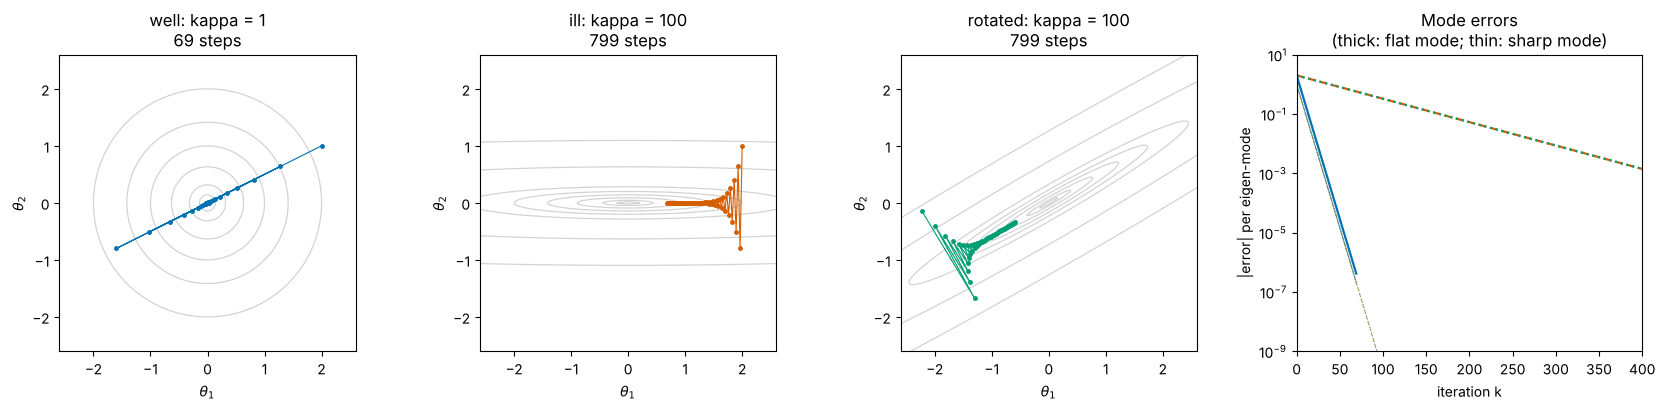

In [8]:
def quad(H, ts):
    return (lambda th: 0.5 * (th - ts) @ H @ (th - ts)), (lambda th: H @ (th - ts))
H_well = np.diag([2.0, 2.0])
H_ill = np.diag([1.0, 100.0])
R30 = np.array([[np.cos(np.radians(30)), -np.sin(np.radians(30))], [np.sin(np.radians(30)), np.cos(np.radians(30))]])
H_rot = R30 @ H_ill @ R30.T
ts0 = np.zeros(2)
z0 = np.array([2.0, 1.0])                                          # initial error in eigen-coordinates (flat mode, sharp mode)
fig, axes = plt.subplots(1, 4, figsize=(17, 4.2))
print(f"{'case':<10}{'eigenvalues':>18}{'kappa':>8}{'eta':>8}{'steps to |grad| < 1e-6':>26}{'multipliers (flat, sharp)':>28}")
for (name, H), c, ls in zip([('well', H_well), ('ill', H_ill), ('rotated', H_rot)], PALETTE, LINESTYLES):
    lam_h, Q_h = np.linalg.eigh(H)
    assert np.all(lam_h > 0), "condition number only defined for positive-definite H"
    th0 = Q_h @ z0                                                   # same eigen-coordinate error in every case
    f, g = quad(H, ts0)
    rr = gradient_descent(f, g, th0, 1.8 / lam_h[-1], max_steps=5000, grad_tol=1e-6)
    print(f"{name:<10}{str(np.round(lam_h, 2)):>18}{lam_h[-1] / lam_h[0]:>8.0f}{1.8 / lam_h[-1]:>8.3f}{rr.n_iter:>26}{str(np.round(1 - 1.8 / lam_h[-1] * lam_h, 3)):>28}  ({rr.stop_reason})")
    ax = axes[['well', 'ill', 'rotated'].index(name)]
    contour_axes(ax, f, (-2.6, 2.6), (-2.6, 2.6), [0.02, 0.1, 0.4, 1, 2, 4] if name == 'well' else [0.02, 0.1, 0.4, 1, 2, 4, 20, 60])
    ax.plot(rr.theta_hist[:60, 0], rr.theta_hist[:60, 1], 'o-', color=c, ms=2.5, lw=0.8)
    ax.set_title(f'{name}: kappa = {lam_h[-1] / lam_h[0]:.0f}\n{rr.n_iter} steps')
    ax.set_xlabel('$\\theta_1$'); ax.set_ylabel('$\\theta_2$')
    Zh = rr.theta_hist @ Q_h
    axes[3].semilogy(np.abs(Zh[:, 0]) + 1e-16, ls, color=c, lw=1.6, label=f'{name}: flat mode')
    axes[3].semilogy(np.abs(Zh[:, 1]) + 1e-16, ls, color=c, lw=0.8, alpha=0.6, label=f'{name}: sharp mode')
axes[3].set_xlim(0, 400); axes[3].set_ylim(1e-9, 10)
axes[3].set_xlabel('iteration k'); axes[3].set_ylabel('|error| per eigen-mode'); axes[3].set_title('Mode errors\n(thick: flat mode; thin: sharp mode)')
plt.tight_layout(); plt.show()

With $\eta = 1.8/\lambda_{\max}$ the sharp mode is multiplied by $1 - 1.8 = -0.8$ every step in every case: it flips sign each step (the zig-zag across the valley) and dies out within a few dozen steps. What remains is the flat mode, multiplied by $1 - 1.8\lambda_{\min}/\lambda_{\max}$: also $-0.8$ for the circular bowl, but $0.982$ for the ill-conditioned ones, which therefore need hundreds of steps (the slow tail in the right panel). Rotation changes the path drawn in $(\theta_1, \theta_2)$ but not the eigenvalues, the number of steps or the mode errors. Contour elongation alone is not a measurement of $\kappa$: it was computed here from the Hessian's spectrum.

#### Interactive version: condition number and learning rate
Each frame shows 40 steps on a rotated quadratic with $\lambda_{\min} = 1$; the slider changes $\lambda_{\max}$ (and so $\kappa$), with $\eta = 1.8/\lambda_{\max}$ (stable, oscillating).

In [9]:
kappas = [1, 2, 4, 8, 16, 32, 64, 128]
xs_k = np.linspace(-2.6, 2.6, 105)
XK, YK = np.meshgrid(xs_k, xs_k)
def kappa_frame(kap):
    H = R30 @ np.diag([1.0, float(kap)]) @ R30.T
    f, g = quad(H, ts0)
    lam_h, Q_h = np.linalg.eigh(H)
    rr = gradient_descent(f, g, Q_h @ z0, 1.8 / lam_h[-1], max_steps=40, grad_tol=1e-9)
    Zg = 0.5 * (H[0, 0] * XK**2 + 2 * H[0, 1] * XK * YK + H[1, 1] * YK**2)
    return Zg, rr
Zg0, rr0 = kappa_frame(kappas[0])
fig_k = go.Figure([go.Contour(x=xs_k, y=xs_k, z=np.round(np.log10(Zg0 + 1e-3), 3), contours=dict(coloring='lines', start=-2, end=2.5, size=0.5), showscale=False, line=dict(width=1), colorscale=[[0, 'lightgrey'], [1, 'grey']]),
                   go.Scatter(x=rr0.theta_hist[:, 0], y=rr0.theta_hist[:, 1], mode='lines+markers', marker=dict(size=5, color=PALETTE[1]), line=dict(color=PALETTE[1]), name='40 steps')])
fr = []
for k, kap in enumerate(kappas):
    Zg, rr = kappa_frame(kap)
    fr.append(go.Frame(name=str(k), data=[go.Contour(z=np.round(np.log10(Zg + 1e-3), 3)), go.Scatter(x=np.round(rr.theta_hist[:, 0], 4), y=np.round(rr.theta_hist[:, 1], 4))],
                       traces=[0, 1], layout=go.Layout(title=f'kappa = {kap}: after 40 steps |error| = {np.linalg.norm(rr.theta_hist[-1]):.2e}  (log-spaced contours)')))
fig_k.frames = fr
buttons, sliders = play_pause_and_slider(kappas, prefix='kappa = ', duration=600)
fig_k.update_layout(title=fr[0].layout.title.text, xaxis=dict(title='theta_1', range=[-2.6, 2.6]), yaxis=dict(title='theta_2', range=[-2.6, 2.6], scaleanchor='x'),
                    template='plotly_white', width=760, height=600, updatemenus=buttons, sliders=sliders)
fig_k.show(config=PLOTLY_CONFIG)

# **Part 4: Scaling, Standardisation and Preconditioning**

### Changing coordinates changes the update geometry
Write the parameters as $\boldsymbol\theta = \mathbf{D}\mathbf{z}$ with an invertible matrix $\mathbf{D}$ (often diagonal: one scale per parameter, $z_i = \theta_i/s_i$). The objective is the same function, $\tilde L(\mathbf{z}) = L(\mathbf{D}\mathbf{z})$, but by the chain rule its gradient is

$$\nabla_{\mathbf{z}}\tilde L = \mathbf{D}^{\mathsf T}\nabla_{\boldsymbol\theta}L ,$$

and gradient descent in $\mathbf{z}$, mapped back to $\boldsymbol\theta$, is

$$\boldsymbol\theta_{k+1} = \mathbf{D}\mathbf{z}_{k+1} = \boldsymbol\theta_k - \eta\,\mathbf{D}\mathbf{D}^{\mathsf T}\nabla_{\boldsymbol\theta}L(\boldsymbol\theta_k):$$

**preconditioned** gradient descent with $\mathbf{P} = \mathbf{D}\mathbf{D}^{\mathsf T}$. The Hessian in $\mathbf{z}$ is $\mathbf{D}^{\mathsf T}\mathbf{H}\mathbf{D}$, whose condition number can be far smaller. The physical objective and its minimiser are unchanged; only the path and speed change. Scaling is a practical special case of preconditioning. Exact inverse-Hessian preconditioning ($\mathbf{P} = \mathbf{H}^{-1}$, Newton's method) is ideal for a quadratic but generally unavailable, expensive or unsafe for large nonconvex problems; adaptive methods such as Adam estimate a diagonal $\mathbf{P}$ on the fly (beyond this lesson).

In [10]:
# Example A: an axis-aligned badly scaled quadratic (a gain in large units and an offset in small ones).
H_a = np.diag([400.0, 1.0]); ts_a = np.array([0.05, 3.0])
fA, gA = quad(H_a, ts_a)
D = np.diag([1 / 20.0, 1.0])                                        # scales chosen so that D^T H D = I here
print("kappa in theta:", np.linalg.cond(H_a), "  kappa in z:", np.linalg.cond(D.T @ H_a @ D))
th0_a = np.array([1.0, 0.0])
res_theta = gradient_descent(fA, gA, th0_a, 1 / 400, max_steps=20000, grad_tol=1e-8)
fz = lambda z: fA(D @ z); gz = lambda z: D.T @ gA(D @ z)
res_z = gradient_descent(fz, gz, np.linalg.solve(D, th0_a), 1.0, max_steps=20000, grad_tol=1e-8)
P = D @ D.T
res_pre = gradient_descent(fA, lambda th: P @ gA(th), th0_a, 1.0, max_steps=20000, grad_tol=1e-8)
print(f"plain GD in theta: {res_theta.n_iter} steps;  GD in z: {res_z.n_iter} steps;  preconditioned GD in theta: {res_pre.n_iter} steps")
print("GD in z mapped back equals preconditioned GD:", np.allclose(res_z.theta_hist @ D.T, res_pre.theta_hist))
print("gradient check of the transformed gradient:", f"{check_gradient(fz, gz, np.array([3.0, 1.0])):.1e}")

kappa in theta: 400.0   kappa in z: 1.0


plain GD in theta: 7798 steps;  GD in z: 1 steps;  preconditioned GD in theta: 1 steps
GD in z mapped back equals preconditioned GD: True
gradient check of the transformed gradient: 8.4e-11


### Feature standardisation in regression, without leakage
For least squares, $L(\boldsymbol\theta) = \frac{1}{2n}\lVert\widetilde{\mathbf{X}}\boldsymbol\theta - \mathbf{y}\rVert^2$ with design $\widetilde{\mathbf{X}}$ (a column of ones and the features), $\nabla L = \frac1n\widetilde{\mathbf{X}}^{\mathsf T}(\widetilde{\mathbf{X}}\boldsymbol\theta - \mathbf{y})$ and $\mathbf{H} = \frac1n\widetilde{\mathbf{X}}^{\mathsf T}\widetilde{\mathbf{X}}$. The loss is convex; it has a unique minimiser only if $\widetilde{\mathbf{X}}$ has full column rank, and $\kappa(\widetilde{\mathbf{X}}^{\mathsf T}\widetilde{\mathbf{X}}) = \kappa(\widetilde{\mathbf{X}})^2$, so forming normal equations squares the conditioning: use `np.linalg.lstsq` as the reference solution.

Features on very different scales and with non-zero means make $\mathbf{H}$ ill-conditioned. **Standardise with training statistics only** ($\mu$, $s$ from the training rows), apply the same transform to validation and test rows, handle constant features (zero SD) explicitly, and map coefficients back: if $\tilde x_j = (x_j - \mu_j)/s_j$ and $\hat y = \tilde b + \sum_j\tilde w_j\tilde x_j$, then $w_j = \tilde w_j/s_j$ and $b = \tilde b - \sum_j\tilde w_j\mu_j/s_j$. Standardisation does **not** fix rank deficiency, collinearity, outliers or leakage.

In [11]:
rng_b = np.random.default_rng(15)
n_b = 120
contrast = rng_b.uniform(0.05, 1.0, n_b)                             # (120,) stimulus contrast, 0-1
duration = rng_b.uniform(100, 500, n_b)                              # (120,) stimulus duration, ms
lum = np.full(n_b, 40.0)                                             # (120,) a constant feature (luminance fixed at 40 cd/m^2)
rate_b = 5 + 30 * contrast + 0.02 * duration + rng_b.normal(0, 2, n_b)   # (120,) spikes/s
Xraw = np.column_stack([contrast, duration, lum])
tr_b = np.arange(n_b) < 80; va_b = ~tr_b
mu_b, sd_b = Xraw[tr_b].mean(axis=0), Xraw[tr_b].std(axis=0)
const = sd_b == 0
print("constant features (zero training SD) dropped:", np.where(const)[0], "-> keeping columns", np.where(~const)[0])
Xk, mu_k, sd_k = Xraw[:, ~const], mu_b[~const], sd_b[~const]
D_raw = np.column_stack([np.ones(n_b), Xk]); D_std = np.column_stack([np.ones(n_b), (Xk - mu_k) / sd_k])
for name, Dm in [('raw', D_raw), ('standardised', D_std)]:
    Hm = Dm[tr_b].T @ Dm[tr_b] / tr_b.sum()
    ev = np.linalg.eigvalsh(Hm)
    fR = lambda th, Dm=Dm: 0.5 * np.mean((Dm[tr_b] @ th - rate_b[tr_b])**2)
    gR = lambda th, Dm=Dm: Dm[tr_b].T @ (Dm[tr_b] @ th - rate_b[tr_b]) / tr_b.sum()
    rr = gradient_descent(fR, gR, np.zeros(3), 1.0 / ev[-1], max_steps=20000, grad_tol=1e-6)
    ref = np.linalg.lstsq(Dm[tr_b], rate_b[tr_b], rcond=None)[0]
    print(f"{name:<13} Hessian eigenvalues {np.round(ev, 5)}  kappa {ev[-1] / ev[0]:>12,.1f};  GD (eta = 1/lambda_max): {rr.n_iter:>5} steps, {rr.stop_reason};  "
          f"max |theta - lstsq| = {np.max(np.abs(rr.theta - ref)):.1e};  validation MSE {np.mean((Dm[va_b] @ rr.theta - rate_b[va_b])**2):.3f}")
    if name == 'standardised':
        th_std = rr.theta
w_back = th_std[1:] / sd_k
b_back = th_std[0] - np.sum(th_std[1:] * mu_k / sd_k)
pred_std = D_std @ th_std; pred_back = b_back + Xk @ w_back
print(f"coefficients mapped back: b = {b_back:.3f}, w = {np.round(w_back, 4)} (true 5, [30, 0.02]);  max |prediction difference| = {np.max(np.abs(pred_std - pred_back)):.1e}")

constant features (zero training SD) dropped: [2] -> keeping columns [0 1]


raw           Hessian eigenvalues [4.09500000e-02 1.78870000e-01 1.06385521e+05]  kappa  2,598,187.2;  GD (eta = 1/lambda_max): 20000 steps, max_steps reached (NOT converged);  max |theta - lstsq| = 2.9e+01;  validation MSE 122.889
standardised  Hessian eigenvalues [0.81286 1.      1.18714]  kappa          1.5;  GD (eta = 1/lambda_max):    14 steps, gradient tolerance;  max |theta - lstsq| = 4.9e-07;  validation MSE 3.695
coefficients mapped back: b = 5.027, w = [2.93118e+01 2.16000e-02] (true 5, [30, 0.02]);  max |prediction difference| = 7.1e-15


On raw features the condition number is in the millions (duration in ms has values in the hundreds, contrast below 1, and the intercept column is far from the feature means). With the stable step $\eta = 1/\lambda_{\max}$, gradient descent is still far from the least-squares solution after 20,000 steps, and its unfinished coefficients give a validation error 30 times larger: an **unconverged** fit can masquerade as a bad model. Standardised, the same problem has condition number about 1.5 and converges in 14 steps; the coefficients mapped back to the original units match the truth and the predictions are identical to machine precision. Scaling changed the **optimisation**, not the model. The constant luminance column would have made the design rank-deficient (it duplicates the intercept); it was detected from the training SD and dropped.

# **Part 5: Stopping and Debugging Clinic**

Each function below contains one common bug. Run them on a quadratic with coupled parameters, $\mathbf{H} = \begin{pmatrix}1 & 2\\ 2 & 10\end{pmatrix}$, and diagnose from **evidence** (histories, gradient check, stop reason), not from the code alone.

In [12]:
f_c, g_c = quad(np.array([[1.0, 2.0], [2.0, 10.0]]), np.array([1.0, -1.0]))     # coupled parameters (eigenvalues 0.6 and 10.4)
th_c = np.array([3.0, 2.0])
def bug_sign(eta=0.1, n=30):
    th = th_c.copy(); hist = [th.copy()]
    for _ in range(n):
        th = th + eta * g_c(th); hist.append(th.copy())          # BUG: + instead of -
    return np.array(hist)
def bug_sequential(eta=0.18, n=60):
    th = th_c.copy(); hist = [th.copy()]
    for _ in range(n):
        th[0] = th[0] - eta * g_c(th)[0]                           # BUG: theta_1 updated before grad_2 is computed
        th[1] = th[1] - eta * g_c(th)[1]
        hist.append(th.copy())
    return np.array(hist)
def bug_nocopy(eta=0.1, n=30):
    th = th_c.copy(); hist = [th]
    for _ in range(n):
        th -= eta * g_c(th); hist.append(th)                       # BUG: in-place update, no .copy(): all entries are the same array
    return np.array(hist)
def bug_normalisation(eta=0.1, n=30):
    # BUG: the gradient of a SUM over 100 identical copies of the data is used with a step tuned for the MEAN.
    th = th_c.copy(); hist = [th.copy()]
    for _ in range(n):
        th = th - eta * 100 * g_c(th); hist.append(th.copy())
        if not np.all(np.isfinite(th)) or np.linalg.norm(th) > 1e12: break
    return np.array(hist)
def bug_false_success(eta=0.002, n=50):
    th = th_c.copy()
    for _ in range(n):
        th = th - eta * g_c(th)
    return th, 'converged'                                         # BUG: reports success after merely running out of steps

good = gradient_descent(f_c, g_c, th_c, 0.1, grad_tol=1e-8)
evidence = {
    'sign error': bug_sign(), 'sequential update': bug_sequential(), 'missing .copy()': bug_nocopy(), 'sum/mean mismatch': bug_normalisation()}
print(f"{'case':<20}{'objective: first -> last':>30}{'distinct stored iterates':>26}")
for name, H_ in evidence.items():
    objs = [f_c(t) for t in H_]
    print(f"{name:<20}{objs[0]:>13.3g} -> {objs[-1]:<13.3g}{len(np.unique(H_.round(12), axis=0)):>26}")
th_fs, status = bug_false_success()
print(f"{'false success':<20} status '{status}', but |grad| = {np.linalg.norm(g_c(th_fs)):.3f} (correct optimiser: '{good.stop_reason}' at |grad| {good.grad_norm_hist[-1]:.1e})")
seq = evidence['sequential update']
print(f"sequential update: reaches the minimum ({np.round(seq[-1], 4)}) but by a different path; the first step differs from the simultaneous step by "
      f"{np.linalg.norm(seq[1] - (th_c - 0.18 * g_c(th_c))):.3f}")

case                      objective: first -> last  distinct stored iterates
sign error                     59 -> 2.38e+20                             31
sequential update              59 -> 3.12e-07                             61
missing .copy()            0.0146 -> 0.0146                                1
sum/mean mismatch              59 -> 8.58e+25                              7
false success        status 'converged', but |grad| = 12.199 (correct optimiser: 'gradient tolerance' at |grad| 9.6e-09)
sequential update: reaches the minimum ([ 1.001  -1.0002]) but by a different path; the first step differs from the simultaneous step by 0.518


| Bug | Evidence | Repair |
|---|---|---|
| sign error | objective **increases** every step from the start; gradient check passes, so the gradient is right and the update is wrong | `theta - eta * grad` |
| sequential update | converges, but along a different path than the simultaneous update; the first step does not match a hand calculation | compute the full gradient once, then update all components |
| missing `.copy()` | every stored iterate is identical (1 distinct value): the history is a list of references to one array | store `theta.copy()` |
| sum/mean mismatch | objective explodes immediately at a learning rate that works for the mean loss: the gradient is 100 times larger than the objective it belongs to | use one normalisation in objective and gradient |
| false success | "converged" while the gradient is far from zero | report "max steps reached", check the gradient norm |

Note what does **not** help: more iterations do not fix a sign error or a normalisation mismatch, and a smaller learning rate merely hides the latter.

# **Part 6: Momentum**

**Heavy-ball momentum**, in the convention used throughout this course:

$$\mathbf{v}_{k+1} = \beta\mathbf{v}_k + \nabla L(\boldsymbol\theta_k),\qquad \boldsymbol\theta_{k+1} = \boldsymbol\theta_k - \eta\,\mathbf{v}_{k+1},\qquad \mathbf{v}_0 = \mathbf{0},\ 0 \le \beta < 1.$$

- $\mathbf{v}$ is **optimiser state** (a running, exponentially weighted sum of past gradients), not a physical velocity. It changes the update dynamics, not the objective.
- $\beta = 0$ recovers vanilla gradient descent with the same $\eta$. (Other texts use $\mathbf{v}_{k+1} = \beta\mathbf{v}_k + (1 - \beta)\nabla L$, which rescales the effective learning rate by $1 - \beta$; never mix conventions in one comparison.)
- In a narrow valley the gradient components across the valley alternate in sign and largely cancel in $\mathbf{v}$, while the small components along the valley add up: momentum damps the zig-zag and accelerates progress along the floor. For quadratics, well-tuned momentum ($\beta$ close to 1) needs about $\sqrt\kappa$ steps per digit instead of $\kappa$.
- It is **not** universally faster, does not guarantee convergence, can overshoot, and its stable $(\eta, \beta)$ region differs from vanilla gradient descent (for quadratics: $0 < \eta\lambda < 2(1 + \beta)$ for every eigenvalue). The objective need not decrease at every step.

beta = 0 reproduces vanilla gradient descent exactly.
ill, vanilla, eta = 1/lmax                          : gradient tolerance                  1902 iterations;  eta lambda_max = 1.00 (stable if < 2(1 + beta) = 2.0)
ill, vanilla, eta = 2/(lmax + lmin)                 : gradient tolerance                  1152 iterations;  eta lambda_max = 1.98 (stable if < 2(1 + beta) = 2.0)


ill, momentum, same eta = 1/lmax, beta = 0.9        : gradient tolerance                   392 iterations;  eta lambda_max = 1.00 (stable if < 2(1 + beta) = 3.8)
ill, tuned momentum (eta = 0.0331, beta = 0.669)    : gradient tolerance                   143 iterations;  eta lambda_max = 3.31 (stable if < 2(1 + beta) = 3.3)
ill, bad momentum (eta = 3.2/lmax, beta = 0.5)      : diverged                              52 iterations;  eta lambda_max = 3.20 (stable if < 2(1 + beta) = 3.0)
well, vanilla, eta = 1/lmax                         : gradient tolerance                     1 iterations;  eta lambda_max = 1.00 (stable if < 2(1 + beta) = 2.0)
well, momentum, eta = 1/lmax, beta = 0.9            : gradient tolerance                     1 iterations;  eta lambda_max = 1.00 (stable if < 2(1 + beta) = 3.8)


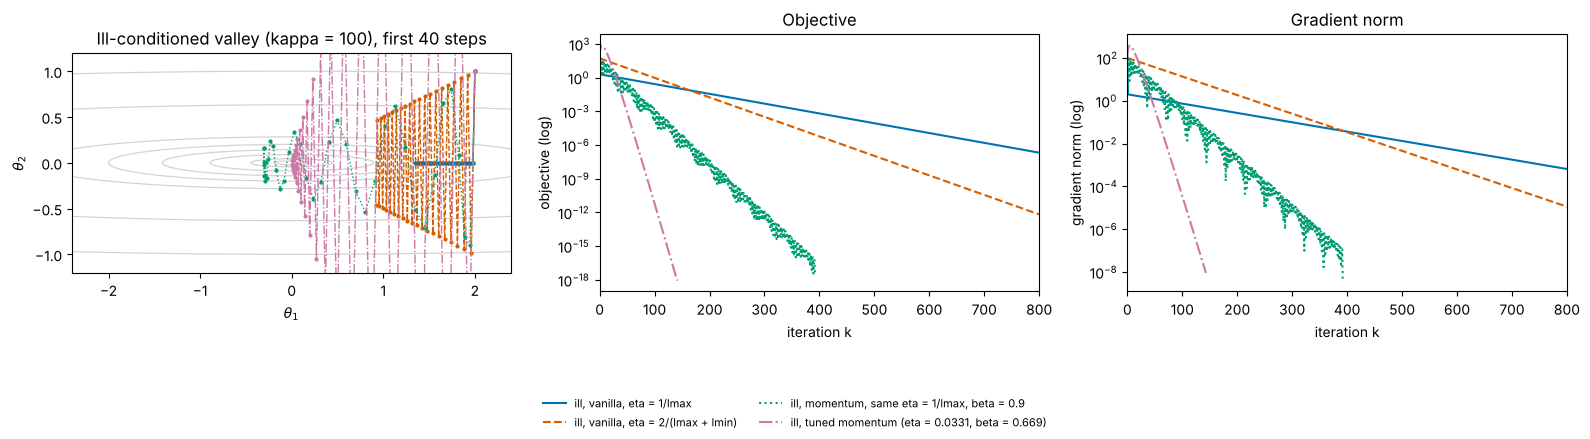

In [13]:
r_vanilla = gradient_descent(f_c, g_c, th_c, 0.1, beta=0.0, grad_tol=1e-8)
r_beta0 = gradient_descent(f_c, g_c, th_c, 0.1, beta=0.0, grad_tol=1e-8)
assert np.array_equal(r_vanilla.theta_hist, r_beta0.theta_hist)
print("beta = 0 reproduces vanilla gradient descent exactly.")

H_ill2 = np.diag([1.0, 100.0]); f_m, g_m = quad(H_ill2, np.zeros(2)); th_m = np.array([2.0, 1.0])
H_w2 = np.diag([2.0, 2.0]); f_w, g_w = quad(H_w2, np.zeros(2))
kap = 100.0
beta_opt = ((np.sqrt(kap) - 1) / (np.sqrt(kap) + 1))**2
eta_opt = 4 / (np.sqrt(100.0) + np.sqrt(1.0))**2
cases = [('ill, vanilla, eta = 1/lmax', f_m, g_m, 1 / 100, 0.0, 100.0), ('ill, vanilla, eta = 2/(lmax + lmin)', f_m, g_m, 2 / 101, 0.0, 100.0),
         ('ill, momentum, same eta = 1/lmax, beta = 0.9', f_m, g_m, 1 / 100, 0.9, 100.0),
         (f'ill, tuned momentum (eta = {eta_opt:.4f}, beta = {beta_opt:.3f})', f_m, g_m, eta_opt, beta_opt, 100.0),
         ('ill, bad momentum (eta = 3.2/lmax, beta = 0.5)', f_m, g_m, 3.2 / 100, 0.5, 100.0),
         ('well, vanilla, eta = 1/lmax', f_w, g_w, 0.5, 0.0, 2.0), ('well, momentum, eta = 1/lmax, beta = 0.9', f_w, g_w, 0.5, 0.9, 2.0)]
mres = []
for name, f, g, e, b, lmx in cases:
    rr = gradient_descent(f, g, th_m, e, beta=b, max_steps=3000, grad_tol=1e-8)
    mres.append(rr)
    print(f"{name:<52}: {rr.stop_reason:<34} {rr.n_iter:5d} iterations;  eta lambda_max = {e * lmx:.2f} (stable if < 2(1 + beta) = {2 * (1 + b):.1f})")
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
contour_axes(axes[0], f_m, (-2.4, 2.4), (-1.2, 1.2), [0.02, 0.1, 0.4, 1, 2, 4, 20, 50])
for rr, (name, *_), c, ls in zip(mres[:4], cases[:4], PALETTE, LINESTYLES):
    axes[0].plot(rr.theta_hist[:40, 0], rr.theta_hist[:40, 1], ls, color=c, lw=1.0, marker='o', ms=2)
    axes[1].semilogy(np.maximum(rr.obj_hist, 1e-18), ls, color=c, lw=1.5, label=name)
    axes[2].semilogy(np.maximum(rr.grad_norm_hist, 1e-18), ls, color=c, lw=1.5)
axes[0].set_title('Ill-conditioned valley (kappa = 100), first 40 steps'); axes[0].set_xlabel('$\\theta_1$'); axes[0].set_ylabel('$\\theta_2$')
axes[1].set_xlabel('iteration k'); axes[1].set_ylabel('objective (log)'); axes[1].set_title('Objective'); axes[1].set_xlim(0, 800)
axes[2].set_xlabel('iteration k'); axes[2].set_ylabel('gradient norm (log)'); axes[2].set_title('Gradient norm'); axes[2].set_xlim(0, 800)
fig.legend(*axes[1].get_legend_handles_labels(), loc='lower center', ncol=2, fontsize=8, frameon=False)
plt.tight_layout(rect=[0, 0.18, 1, 1]); plt.show()

On the ill-conditioned valley, vanilla gradient descent needs about 1,900 steps with $\eta = 1/\lambda_{\max}$ (and about 1,150 with the best constant step $2/(\lambda_{\max} + \lambda_{\min})$). Momentum with $\beta = 0.9$ at the same $\eta$ needs about 390, and tuned momentum ($\beta \approx 0.67$) about 140: a fair comparison tunes each method's hyperparameters, not just the "same $\eta$". On the well-conditioned bowl, vanilla gradient descent with $\eta = 1/\lambda$ finishes in one step and momentum only adds oscillation. A bad pair ($\eta\lambda_{\max} = 3.2 > 2(1 + 0.5)$) diverges.

#### Interactive version: the momentum coefficient

In [14]:
betas = [0.0, 0.3, 0.5, 0.7, 0.8, 0.85, 0.9, 0.95, 0.98]
xs_m, ys_m = np.linspace(-2.4, 2.4, 121), np.linspace(-1.2, 1.2, 61)
Zm = 0.5 * (np.meshgrid(xs_m, ys_m)[0]**2 + 100 * np.meshgrid(xs_m, ys_m)[1]**2)
def mom_frame(b):
    return gradient_descent(f_m, g_m, th_m, 1 / 100, beta=b, max_steps=150, grad_tol=1e-10)
rm0 = mom_frame(betas[0])
fig_m = go.Figure([go.Contour(x=xs_m, y=ys_m, z=np.round(np.log10(Zm + 1e-3), 3), contours=dict(coloring='lines', start=-2, end=2.5, size=0.5), showscale=False, line=dict(width=1), colorscale=[[0, 'lightgrey'], [1, 'grey']]),
                   go.Scatter(x=rm0.theta_hist[:, 0], y=rm0.theta_hist[:, 1], mode='lines+markers', marker=dict(size=4, color=PALETTE[1]), line=dict(color=PALETTE[1]), name='150 steps')])
frm = []
for k, b in enumerate(betas):
    rr = mom_frame(b)
    frm.append(go.Frame(name=str(k), traces=[1], data=[go.Scatter(x=np.round(rr.theta_hist[:, 0], 4), y=np.round(rr.theta_hist[:, 1], 4))],
                        layout=go.Layout(title=f'beta = {b}, eta = 0.01: objective after 150 steps {rr.obj_hist[-1]:.2e} ({rr.stop_reason})')))
fig_m.frames = frm
buttons, sliders = play_pause_and_slider(betas, prefix='beta = ', duration=600)
fig_m.update_layout(title=frm[0].layout.title.text, xaxis=dict(title='theta_1', range=[-2.4, 2.4]), yaxis=dict(title='theta_2', range=[-1.2, 1.2], scaleanchor='x'),
                    template='plotly_white', width=850, height=480, updatemenus=buttons, sliders=sliders)
fig_m.show(config=PLOTLY_CONFIG)

# **Part 7: Nonconvex Objectives: Starts, Basins and Saddles**

On a nonconvex objective, a zero gradient is a **stationary point**, not necessarily a minimum, and the end point depends on the start (Lessons 11, 12). A bounded example with two minima and a saddle:

$$L(x, y) = (x^2 - 1)^2 + 2y^2 + 0.3\,x,$$

with a deeper minimum near $x = -1.04$, a shallower one near $x = 0.96$, and a saddle near $x = 0.075$, $y = 0$.

gradient check: 2.8e-11
start [-1.5  1. ]: ends at [-1.0356  0.    ], L = -0.3054, Hessian eigenvalues [4.   8.87] (gradient tolerance)
start [-0.2 -1. ]: ends at [-1.0356 -0.    ], L = -0.3054, Hessian eigenvalues [4.   8.87] (gradient tolerance)
start [0.3 1.2]: ends at [0.9601 0.    ], L = +0.2941, Hessian eigenvalues [4.   7.06] (gradient tolerance)
start [ 1.4 -0.8]: ends at [ 0.9601 -0.    ], L = +0.2941, Hessian eigenvalues [4.   7.06] (gradient tolerance)
start [0.05 0.9 ]: ends at [-1.0356  0.    ], L = -0.3054, Hessian eigenvalues [4.   8.87] (gradient tolerance)


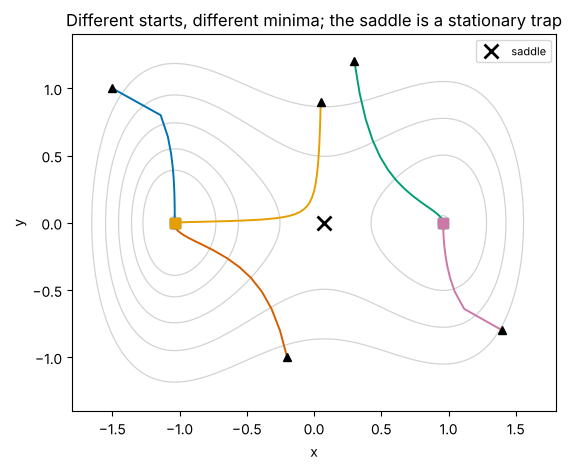

start exactly at the saddle: stops immediately (gradient tolerance, 0 iterations, |grad| = 5.6e-17) at a point that is NOT a minimum
start 1e-6 to the right of the saddle: ends at [0.9601 0.    ] after 122 iterations


In [15]:
fN = lambda th: (th[0]**2 - 1)**2 + 2 * th[1]**2 + 0.3 * th[0]
gN = lambda th: np.array([4 * th[0] * (th[0]**2 - 1) + 0.3, 4 * th[1]])
print("gradient check:", f"{check_gradient(fN, gN, np.array([0.4, -0.3])):.1e}")
xs_crit = np.sort(np.roots([4, 0, -4, 0.3]).real)
saddle = np.array([xs_crit[1], 0.0])
starts = np.array([[-1.5, 1.0], [-0.2, -1.0], [0.3, 1.2], [1.4, -0.8], [0.05, 0.9]])
fig, ax = plt.subplots(figsize=(8, 4.8))
contour_axes(ax, fN, (-1.8, 1.8), (-1.4, 1.4), [-1.2, -0.9, -0.6, -0.3, 0, 0.3, 0.8, 1.5, 2.5])
for s0, c in zip(starts, PALETTE):
    rr = gradient_descent(fN, gN, s0, 0.05, max_steps=5000, grad_tol=1e-8)
    ax.plot(rr.theta_hist[:, 0], rr.theta_hist[:, 1], '-', color=c, lw=1.4); ax.plot(*s0, 'k^', ms=6); ax.plot(*rr.theta, 's', color=c, ms=7)
    H_end = np.array([[12 * rr.theta[0]**2 - 4, 0], [0, 4]])
    print(f"start {s0}: ends at {np.round(rr.theta, 4)}, L = {rr.objective:+.4f}, Hessian eigenvalues {np.round(np.linalg.eigvalsh(H_end), 2)} ({rr.stop_reason})")
ax.plot(*saddle, 'kx', ms=10, mew=2, label='saddle')
r_sad = gradient_descent(fN, gN, saddle, 0.05, max_steps=500, grad_tol=1e-12)
r_pert = gradient_descent(fN, gN, saddle + np.array([1e-6, 0]), 0.05, max_steps=5000, grad_tol=1e-8)
ax.set_xlabel('x'); ax.set_ylabel('y'); ax.set_title('Different starts, different minima; the saddle is a stationary trap'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
print(f"start exactly at the saddle: stops immediately ({r_sad.stop_reason}, {r_sad.n_iter} iterations, |grad| = {r_sad.grad_norm_hist[-1]:.1e}) at a point that is NOT a minimum")
print(f"start 1e-6 to the right of the saddle: ends at {np.round(r_pert.theta, 4)} after {r_pert.n_iter} iterations")

A small gradient norm alone is ambiguous: at the saddle it is exactly zero, yet the point is not a minimum (the Hessian has a negative eigenvalue). One run from one start is never evidence of a global minimum; multiple starts and a check of the Hessian at the end are.

# **Part 8: Mini-Lab — Training a Motor-Cortex Decoder by Gradient Descent**

We fit the linear decoder of Lesson 5, hand velocity from 170 neurons' smoothed rates ([Stevenson et al., 2011](https://doi.org/10.1152/jn.00626.2010); [DREAM on CRCNS](https://crcns.org/data-sets/movements/dream); packaged by [Benjamin et al., 2018](https://github.com/KordingLab/spykesML)), by **gradient descent**, with $p = 171$ parameters per velocity component:

$$L(\mathbf{W}) = \frac{1}{2n}\lVert\widetilde{\mathbf{X}}\mathbf{W} - \mathbf{Y}\rVert_F^2,\qquad \widetilde{\mathbf{X}}: (n, 171),\ \mathbf{W}: (171, 2),\ \mathbf{Y}: (n, 2)\ \text{(cm/s)}.$$

**Splits (chronological).** Training: the first **10%** of the session (about 78 s, deliberately little data); validation: the next 10%; test: the second half, used **once** at the end. Scaler statistics come from the training rows only.

**Plan.**
1. Conditioning: raw rates (spikes/s, with an intercept) against standardised rates.
2. Gradient descent and momentum on both, against the `lstsq` reference.
3. Training versus validation histories: when does further optimisation stop helping?
4. Ridge regularisation, with $\lambda$ chosen on validation; one final test.

In [16]:
import os, urllib.request
from scipy.io import loadmat
from scipy.ndimage import gaussian_filter1d

M1_FILE = 'm1_stevenson_2011.mat'
if not os.path.exists(M1_FILE):
    urllib.request.urlretrieve('https://raw.githubusercontent.com/KordingLab/spykesML/ff2b1830ae07909e5f1a0811445ca3fd5732dc6f/data/' + M1_FILE, M1_FILE)
m1 = loadmat(M1_FILE)
rates = m1['spikes'].T.astype(float) / 0.05                           # (15536, 171) spikes/s
vel = m1['handVel'][:2].T * 100                                        # (15536, 2) cm/s
X_all = gaussian_filter1d(rates, 1, axis=0)[:-2]                      # (15534, 171) rates smoothed over ~50 ms
Y_all = vel[2:]                                                        # (15534, 2) velocity 100 ms later
n_all = len(X_all); idx = np.arange(n_all)
tr = idx < int(0.1 * n_all); va = (idx >= int(0.1 * n_all)) & (idx < int(0.2 * n_all)); te = idx >= n_all // 2
mu_x, sd_x = X_all[tr].mean(axis=0), X_all[tr].std(axis=0)
keep = sd_x > 0                                                        # neurons silent in the training rows cannot be standardised
print(f"train {tr.sum()} bins, validation {va.sum()}, test {te.sum()};  neurons kept {keep.sum()} of 171 (zero training SD: {np.where(~keep)[0]})")
Xr = np.column_stack([np.ones(n_all), X_all[:, keep]])                 # raw design, (n, p)
Xs = np.column_stack([np.ones(n_all), (X_all[:, keep] - mu_x[keep]) / sd_x[keep]])   # standardised with TRAINING statistics
def r2(P, Yt):
    return 1 - np.sum((Yt - P)**2, axis=0) / np.sum((Yt - Yt.mean(axis=0))**2, axis=0)
for name, Xd in [('raw', Xr), ('standardised', Xs)]:
    Hd = Xd[tr].T @ Xd[tr] / tr.sum()
    ev = np.linalg.eigvalsh(Hd)
    print(f"{name:<13}: Hessian eigenvalues {ev[0]:.2e} ... {ev[-1]:.2e}, kappa = {ev[-1] / ev[0]:,.0f};  design rank {np.linalg.matrix_rank(Xd[tr])} of {Xd.shape[1]}")

train 1553 bins, validation 1553, test 7767;  neurons kept 167 of 171 (zero training SD: [ 21  42  54 155])
raw          : Hessian eigenvalues 1.60e-03 ... 1.56e+05, kappa = 97,498,660;  design rank 168 of 168
standardised : Hessian eigenvalues 1.17e-01 ... 1.89e+01, kappa = 161;  design rank 168 of 168


In [17]:
def fit_gd(Xd, eta_scale=1.0, beta=0.0, steps=2000, lam=0.0, record_every=1):
    # Full-batch (heavy-ball) gradient descent on the (optionally ridge-penalised) mean squared error, both outputs at once.
    Xt, Yt = Xd[tr], Y_all[tr]; n = len(Xt)
    pen = np.ones(Xd.shape[1]); pen[0] = 0                             # the intercept is not penalised
    Hd = Xt.T @ Xt / n + lam / n * np.diag(pen)
    eta = eta_scale / np.linalg.eigvalsh(Hd)[-1]
    W = np.zeros((Xd.shape[1], 2)); V = np.zeros_like(W); hist = []
    for k in range(steps + 1):
        if k % record_every == 0:
            hist.append((k, 0.5 * np.mean(np.sum((Xt @ W - Yt)**2, axis=1)), r2(Xd[va] @ W, Y_all[va]).mean()))
        G = Xt.T @ (Xt @ W - Yt) / n + lam / n * pen[:, None] * W
        V = beta * V + G
        W = W - eta * V
    return W, np.array(hist)

W_ref = {nm: np.linalg.lstsq(Xd[tr], Y_all[tr], rcond=None)[0] for nm, Xd in [('raw', Xr), ('standardised', Xs)]}
L_ref = 0.5 * np.mean(np.sum((Xs[tr] @ W_ref['standardised'] - Y_all[tr])**2, axis=1))
print(f"lstsq reference: training loss {L_ref:.2f} (cm/s)^2, validation R^2 (mean of vx, vy) {r2(Xs[va] @ W_ref['standardised'], Y_all[va]).mean():.3f}")
runs_ml = {}
for nm, Xd in [('raw', Xr), ('standardised', Xs)]:
    for beta in [0.0, 0.9]:
        W, h = fit_gd(Xd, beta=beta, steps=3000)
        runs_ml[(nm, beta)] = h
        excess = (h[:, 1] - L_ref) / L_ref
        hit = np.argmax(excess < 0.01) if np.any(excess < 0.01) else None
        print(f"{nm:<13} beta = {beta}: after 3000 steps excess training loss {excess[-1]:.2e};  "
              f"steps to within 1% of the optimum: {hit if hit is not None else '> 3000'}")

lstsq reference: training loss 6.79 (cm/s)^2, validation R^2 (mean of vx, vy) 0.639


raw           beta = 0.0: after 3000 steps excess training loss 2.39e-01;  steps to within 1% of the optimum: > 3000


raw           beta = 0.9: after 3000 steps excess training loss 7.68e-02;  steps to within 1% of the optimum: > 3000


standardised  beta = 0.0: after 3000 steps excess training loss 0.00e+00;  steps to within 1% of the optimum: 113


standardised  beta = 0.9: after 3000 steps excess training loss -1.31e-16;  steps to within 1% of the optimum: 51


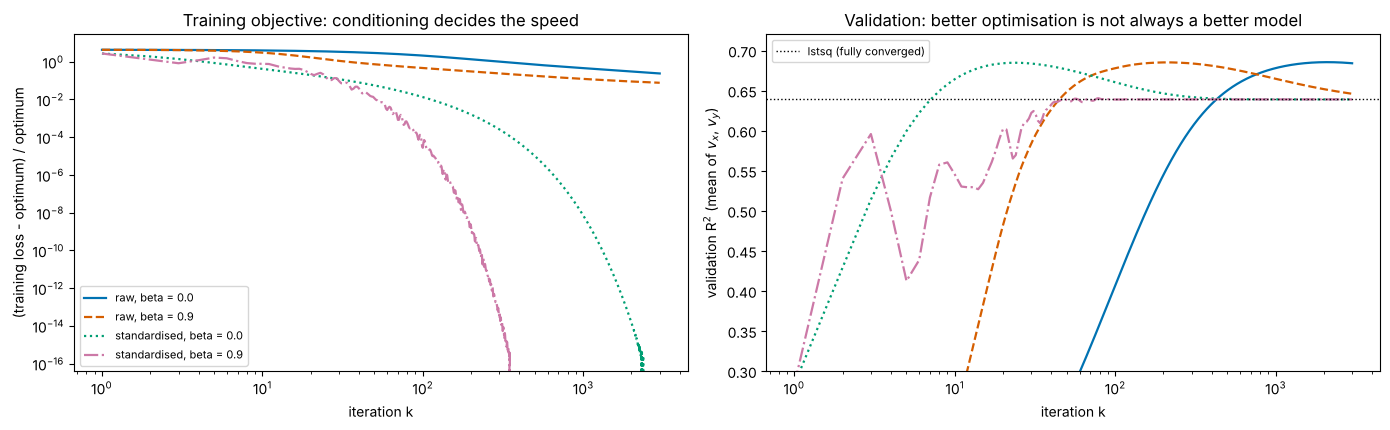

standardised, vanilla: validation R^2 peaks at 0.685 after 24 steps, then falls to 0.639 as the training loss converges


In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
for (key, h), c, ls in zip(runs_ml.items(), PALETTE, LINESTYLES):
    axes[0].loglog(h[1:, 0], (h[1:, 1] - L_ref) / L_ref, ls, color=c, lw=1.6, label=f'{key[0]}, beta = {key[1]}')
    axes[1].semilogx(h[1:, 0], h[1:, 2], ls, color=c, lw=1.6)
axes[1].axhline(r2(Xs[va] @ W_ref['standardised'], Y_all[va]).mean(), color='black', ls=':', lw=1, label='lstsq (fully converged)')
axes[0].set_xlabel('iteration k'); axes[0].set_ylabel('(training loss - optimum) / optimum'); axes[0].set_title('Training objective: conditioning decides the speed'); axes[0].legend(fontsize=8)
axes[1].set_xlabel('iteration k'); axes[1].set_ylabel('validation R$^2$ (mean of $v_x$, $v_y$)'); axes[1].set_title('Validation: better optimisation is not always a better model')
axes[1].set_ylim(0.3, 0.72); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()
h_std = runs_ml[('standardised', 0.0)]
k_best = int(h_std[np.argmax(h_std[:, 2]), 0])
print(f"standardised, vanilla: validation R^2 peaks at {h_std[:, 2].max():.3f} after {k_best} steps, then falls to {h_std[-1, 2]:.3f} as the training loss converges")

### Ridge regularisation, chosen on validation

With the normalisation $L_{\text{reg}}(\mathbf{W}) = \frac{1}{2n}\lVert\widetilde{\mathbf{X}}\mathbf{W} - \mathbf{Y}\rVert_F^2 + \frac{\lambda}{2n}\lVert\mathbf{W}_{\text{weights}}\rVert_F^2$ (intercept **not** penalised, so the decoder is not pulled towards zero velocity offset), the gradient gains $\frac{\lambda}{n}\mathbf{W}_{\text{weights}}$ and the Hessian gains $\frac{\lambda}{n}$ on every penalised eigen-direction (Lesson 11). The penalty changes the **statistical target** as well as the geometry.

In [19]:
lams = [0, 30, 100, 300, 1000, 3000, 10000]
pen = np.ones(Xs.shape[1]); pen[0] = 0
print(f"{'lambda':>8}{'kappa':>10}{'train R^2':>12}{'validation R^2':>16}")
best = None
for lam in lams:
    Hd = Xs[tr].T @ Xs[tr] / tr.sum() + lam / tr.sum() * np.diag(pen)
    W = np.linalg.solve(Hd, Xs[tr].T @ Y_all[tr] / tr.sum())             # small (171 x 171) system; lstsq/SVD would also do
    ev = np.linalg.eigvalsh(Hd)
    vr = r2(Xs[va] @ W, Y_all[va]).mean()
    print(f"{lam:>8}{ev[-1] / ev[0]:>10.1f}{r2(Xs[tr] @ W, Y_all[tr]).mean():>12.3f}{vr:>16.3f}")
    if best is None or vr > best[1]:
        best = (lam, vr, W)
lam_best, _, W_best = best
W_ridge_gd, h_ridge = fit_gd(Xs, beta=0.9, steps=1500, lam=lam_best)
print(f"\nchosen lambda = {lam_best} (validation);  gradient descent with momentum reaches the ridge solution: max |W_gd - W_ridge| = {np.max(np.abs(W_ridge_gd - W_best)):.1e}")
print("FINAL TEST (used once):")
print(f"  unregularised least squares:   test R^2 {np.round(r2(Xs[te] @ W_ref['standardised'], Y_all[te]), 3)}")
print(f"  ridge, lambda = {lam_best:<6}:       test R^2 {np.round(r2(Xs[te] @ W_best, Y_all[te]), 3)}")
W_es, _ = fit_gd(Xs, steps=k_best)
print(f"  early stopping at {k_best} steps:   test R^2 {np.round(r2(Xs[te] @ W_es, Y_all[te]), 3)}")

  lambda     kappa   train R^2  validation R^2
       0     161.2       0.815           0.639
      30     138.6       0.815           0.648
     100     104.5       0.813           0.661
     300      61.6       0.804           0.677
    1000      25.7       0.765           0.672
    3000      20.9       0.669           0.606
   10000      25.4       0.462           0.425



chosen lambda = 300 (validation);  gradient descent with momentum reaches the ridge solution: max |W_gd - W_ridge| = 7.8e-15
FINAL TEST (used once):
  unregularised least squares:   test R^2 [0.658 0.438]
  ridge, lambda = 300   :       test R^2 [0.677 0.504]
  early stopping at 24 steps:   test R^2 [0.667 0.52 ]


**Interpretation.**
- **Conditioning.** On raw rates the Hessian's condition number is about $10^8$ (the intercept column and rates of tens of spikes/s live on very different scales, and neurons are correlated). Gradient descent with a stable step makes slow progress even after 3,000 steps; momentum helps but does not cure it. Standardised with training statistics, the condition number is in the hundreds and gradient descent reaches the least-squares optimum within about 1% in tens of steps. The fitted decoder is the same model either way.
- **Optimisation is not the goal.** With only 78 s of training data, validation $R^2$ peaks early in the run and then **falls** as gradient descent drives the training loss to its minimum: the decoder overfits the training noise. Early stopping (chosen on validation) and ridge regularisation (with $\lambda$ chosen on validation) both trade a slightly higher training loss for better held-out performance, and both beat the fully converged least-squares decoder on the test half.
- **Three separate questions.** *Optimisation*: did the algorithm reach the minimum of the objective we wrote down (check gradient norm, reference solution)? *Prediction*: does the fitted decoder generalise (validation for decisions, test once)? *Science*: what do the weights say about the neurons? Correlated neurons make individual weights weakly identified (Lesson 11), whatever the optimiser does.

**Limitations.** One session; a linear decoder at a single lag; chronological splits mix overfitting with non-stationarity; the validation set was used for several decisions ($\lambda$, stopping step), so its score is optimistic, which is why the test half was kept separate.

# **Part 9: From Two Parameters to Many, and Applications**

The optimiser code works unchanged for any shape `(p,)`: in the mini-lab $p = 171 \times 2$. Two-dimensional contour plots are **slices** of a high-dimensional landscape, useful for intuition but not the whole picture. Backpropagation (Lesson 10) **computes** gradients; the optimiser decides **updates**. Full-batch gradients cost one pass over the data per step; mini-batch gradients (Lesson 12) trade noise for cost. Automatic differentiation is tooling, not a replacement for gradient checks and shape checks.

| Idea | Neuroscience | Machine learning |
|---|---|---|
| Vector gradient descent | fitting GLMs, decoders, receptive fields; models of synaptic learning rules | training every neural network |
| Eigenmodes and $\eta < 2/\lambda_{\max}$ | stability of learning dynamics; eigenvalues of the Jacobian (Lesson 23) | learning-rate limits; "loss explodes" |
| Condition number | correlated neurons and features; sloppy biophysical models | slow training; need for normalisation |
| Scaling and preconditioning | parameter units in biophysical fits (mV, ms, nS) | standardisation, batch normalisation, Adam/RMSProp (diagonal preconditioners) |
| Momentum | — (a property of the optimiser, not evidence that brains use momentum) | SGD with momentum, Nesterov, Adam |
| Regularisation and validation | ridge decoders and receptive-field models; cross-validated model comparison | weight decay, early stopping, held-out monitoring |
| Diagnostics and reproducibility | trustworthy model fits in papers | seeded runs, logged histories, reported stop reasons |

# **Part 10: Summary, Exit Ticket and Lesson 16 Preview**

| Idea | Formula / code | What to remember |
|---|---|---|
| Vector update | $\boldsymbol\theta_{k+1} = \boldsymbol\theta_k - \eta\nabla L(\boldsymbol\theta_k)$ | simultaneous; record histories from iteration 0 |
| Quadratic error | $\mathbf{e}_{k+1} = (\mathbf{I} - \eta\mathbf{H})\mathbf{e}_k$; $z_{i,k+1} = (1 - \eta\lambda_i)z_{i,k}$ | each eigen-direction on its own |
| Stability | $0 < \eta < 2/\lambda_{\max}$ (quadratic) | boundary = marginal, not convergent; local guidance elsewhere |
| Rate | $\rho = \max_i\lvert1 - \eta\lambda_i\rvert$; best constant step gives $\frac{\kappa - 1}{\kappa + 1}$ | the flat mode sets the tail |
| Condition number | $\kappa = \lambda_{\max}/\lambda_{\min}$ (positive definite) | depends on units and parameterisation |
| Scaling / preconditioning | $\boldsymbol\theta = \mathbf{D}\mathbf{z}$ ⇔ $\boldsymbol\theta_{k+1} = \boldsymbol\theta_k - \eta\mathbf{D}\mathbf{D}^{\mathsf T}\nabla L$ | changes geometry, not the objective; training-only statistics |
| Momentum | $\mathbf{v}_{k+1} = \beta\mathbf{v}_k + \nabla L$, $\boldsymbol\theta_{k+1} = \boldsymbol\theta_k - \eta\mathbf{v}_{k+1}$ | damps zig-zag; own stable region; not always faster |
| Stopping | gradient, step and objective tolerances; iteration cap; finite checks | report the stop reason; max steps ≠ converged |
| Regularisation | $+\frac{\lambda}{2n}\lVert\mathbf{w}\rVert^2$ (intercept unpenalised) | choose $\lambda$ and stopping on validation; test once |

**Exit ticket.** A colleague's fit "converged" after 5,000 steps with a final loss that looks flat on a linear-scale plot. List three numbers you would ask for before believing it, and what each could reveal.

*(Suggested answer: the gradient norm at the end (still large? then not converged); the stop reason (iteration limit?); the Hessian's spectrum or condition number in the chosen units (a flat direction or poor scaling makes "flat-looking" plots misleading); and, for prediction, the validation error over iterations.)*

**Lesson 16 — Probability rules.** The noise in spike counts, the trial-to-trial variability of decisions, and the uncertainty in fitted parameters all call for a language of chance. Week 5 begins with the rules of probability: joint, conditional and marginal probabilities, independence, and the law of total probability.

**Further reading.** S. Boyd and L. Vandenberghe, *Convex Optimization* (2004), Chapter 9; G. Goh, "Why momentum really works", *Distill* (2017); L. Bottou, F. E. Curtis and J. Nocedal, "Optimization methods for large-scale machine learning", *SIAM Review* 60 (2018); I. Goodfellow, Y. Bengio and A. Courville, *Deep Learning* (2016), Chapter 8.